# Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 27/proyecto")


# Carga de los datos

In [2]:
cat = pd.read_csv("DIM_CATEGORY (2).csv")
prod = pd.read_excel("DIM_PRODUCT (1).xlsx")
sales = pd.read_csv("FACT_SALES (1).csv")

print("DIM_CATEGORY:", cat.shape)
print("DIM_PRODUCT:", prod.shape)
print("FACT_SALES:", sales.shape)

DIM_CATEGORY: (5, 2)
DIM_PRODUCT: (505, 9)
FACT_SALES: (122002, 6)


# Exploración inicial

In [3]:
display(prod.head())
display(sales.head())
print("\nColumnas de productos:", prod.columns.tolist())
print("\nColumnas de ventas:", sales.columns.tolist())
print("\nValores de marca que contienen VANISH:")
display(prod[prod["BRAND"].astype(str).str.contains("VANISH", case=False, na=False)]["BRAND"].value_counts())

,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,INDS. ALEN,CLORALEX,0000075000592,CLORALEX EL RENDIDOR BOT.PLAST. 250ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
1,INDS. ALEN,CLORALEX,0000075000608,CLORALEX EL RENDIDOR BOT.PLAST. 500ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
2,INDS. ALEN,CLORALEX,0000075000615,CLORALEX EL RENDIDOR BOT.PLAST. 950ML NAL. 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
3,INDS. ALEN,CLORALEX,0000075000622,CLORALEX EL RENDIDOR BOT.PLAST. 2000ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
4,INDS. ALEN,CLORALEX,0000075000639,CLORALEX EL RENDIDOR BOT.PLAST. 3750ML NAL 000...,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO


,WEEK,ITEM_CODE,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES,REGION
0,34-22,7501058792808BP2,0.006,0.139,1.000,TOTAL AUTOS AREA 5
1,34-22,7501058715883,0.487,116.519,2.916,TOTAL AUTOS AREA 5
2,34-22,7702626213774,1.391,68.453,5.171,TOTAL AUTOS AREA 5
3,34-22,7501058716422,0.022,1.481,1.833,TOTAL AUTOS AREA 5
4,34-22,7501058784353,2.037,182.839,5.375,TOTAL AUTOS AREA 5



Columnas de productos: ['MANUFACTURER', 'BRAND', 'ITEM', 'ITEM_DESCRIPTION', 'CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3']

Columnas de ventas: ['WEEK', 'ITEM_CODE', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION']

Valores de marca que contienen VANISH:


BRAND
VANISH                  103
VANISH PODER 02          10
VANISH CRYSTAL WHITE      4
VANISH EXTRA HIGIENE      1
Name: count, dtype: int64

# Preparación e integración

Se utiliza `ITEM` de la dimensión de productos y `ITEM_CODE` de la tabla de ventas como llave. Se conservan los productos cuya marca contiene **VANISH**, incluyendo variantes comerciales de la marca.

In [4]:
prod["ITEM"] = prod["ITEM"].astype(str).str.strip()
sales["ITEM_CODE"] = sales["ITEM_CODE"].astype(str).str.strip()

van = prod[prod["BRAND"].astype(str).str.contains("VANISH", case=False, na=False)].copy()

vs = sales.merge(
    van,
    left_on="ITEM_CODE",
    right_on="ITEM",
    how="inner"
)

print("Productos Vanish en catálogo:", len(van))
print("Registros de ventas Vanish:", len(vs))
print("Productos Vanish con ventas:", vs["ITEM_CODE"].nunique())

Productos Vanish en catálogo: 118
Registros de ventas Vanish: 28377
Productos Vanish con ventas: 77


 # Agregación de indicadores comerciales

In [5]:
agg = (
    vs.groupby("ITEM_CODE")
      .agg(
          total_units=("TOTAL_UNIT_SALES", "sum"),
          total_value=("TOTAL_VALUE_SALES", "sum"),
          avg_weekly_units=("TOTAL_UNIT_AVG_WEEKLY_SALES", "mean"),
          weeks=("WEEK", "nunique"),
          regions=("REGION", "nunique")
      )
      .reset_index()
      .merge(
          van[["ITEM", "BRAND", "ITEM_DESCRIPTION", "CATEGORY", "FORMAT", "ATTR1", "ATTR2", "ATTR3"]],
          left_on="ITEM_CODE",
          right_on="ITEM",
          how="left"
      )
)

display(agg.head())
display(agg[["total_units","total_value","avg_weekly_units","weeks","regions"]].describe().round(2))

,ITEM_CODE,total_units,total_value,avg_weekly_units,weeks,regions,ITEM,BRAND,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
0,7501058712813,0.586,28.885,1.834403,55,7,7501058712813,VANISH,VANISH OXI ACTION QUITAMANCHAS P/ROPA BOTE 240...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
1,7501058713780,0.162,3.580,1.507847,35,7,7501058713780,VANISH,VANISH OXI ACTION ROSA QUITA MANCHAS PARA LA R...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,ROSA
2,7501058714596,8059.988,99483.947,21.142191,80,7,7501058714596,VANISH,VANISH SUPER BARRA QUITA MANCHAS 68GR 75010587...,1,BARRA,SAFE BLEACH,FABRIC TREATMENT,ROSA
3,7501058715012,0.118,3.106,1.263884,26,7,7501058715012,VANISH,VANISH OXI ACTION CRISTAL WHITE BOT 150GR 7501...,1,POLVO,SAFE BLEACH,FABRIC TREATMENT,BLANCO
4,7501058715029,0.092,1.784,5.111111,9,3,7501058715029,VANISH,VANISH MULTIUSOS REMOVEDOR S/CLORO DE MANCHAS ...,1,LIQUIDO,SAFE BLEACH,FABRIC TREATMENT,ROSA


,total_units,total_value,avg_weekly_units,weeks,regions
count,77.00,77.00,77.00,77.0,77.00
mean,718.61,28159.60,4.82,61.7,6.22
std,1596.56,41251.43,5.90,28.0,1.55
min,0.00,0.01,0.12,1.0,2.00
25%,0.59,28.88,1.98,42.0,7.00
50%,67.46,4429.77,2.77,80.0,7.00
75%,582.63,50615.94,4.78,80.0,7.00
max,8059.99,162102.97,31.71,80.0,7.00


# Variables seleccionadas

Para el clustering se consideran:
- **total_units:** unidades vendidas acumuladas.
- **total_value:** valor de ventas acumulado.
- **avg_weekly_units:** promedio semanal de unidades.
- **weeks:** número de semanas con registro.
- **regions:** número de regiones con presencia.

Las variables de ventas presentan fuerte asimetría; por ello se aplica `log1p` antes de estandarizar.

In [6]:
features = ["total_units", "total_value", "avg_weekly_units", "weeks", "regions"]

prep = pd.concat(
    [
        np.log1p(agg[["total_units", "total_value", "avg_weekly_units"]]),
        agg[["weeks", "regions"]]
    ],
    axis=1
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(prep)

print("Matriz para clustering:", X_scaled.shape)

Matriz para clustering: (77, 5)


# Método del codo y coeficiente de silueta

In [7]:
evaluacion = []

for k in range(2, 9):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = modelo.fit_predict(X_scaled)
    evaluacion.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)
    })

evaluacion_df = pd.DataFrame(evaluacion)
display(evaluacion_df.round(4))

,k,inercia,silhouette
0,2,163.9355,0.5290
1,3,108.0473,0.4562
2,4,69.4366,0.4919
3,5,54.1385,0.5219
4,6,42.6467,0.4593
5,7,33.3390,0.4746
6,8,27.8534,0.4769


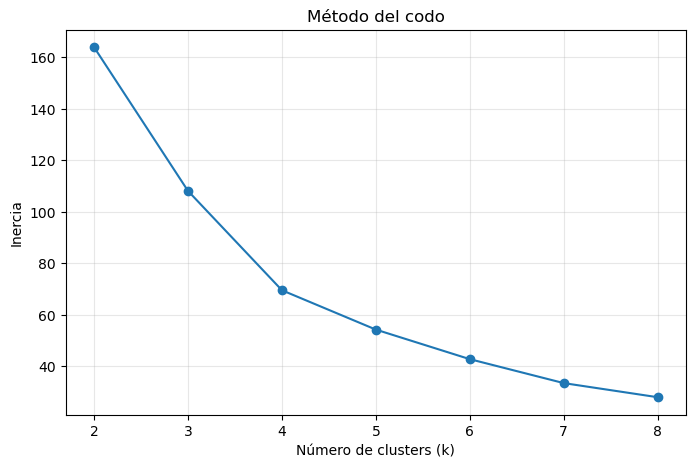

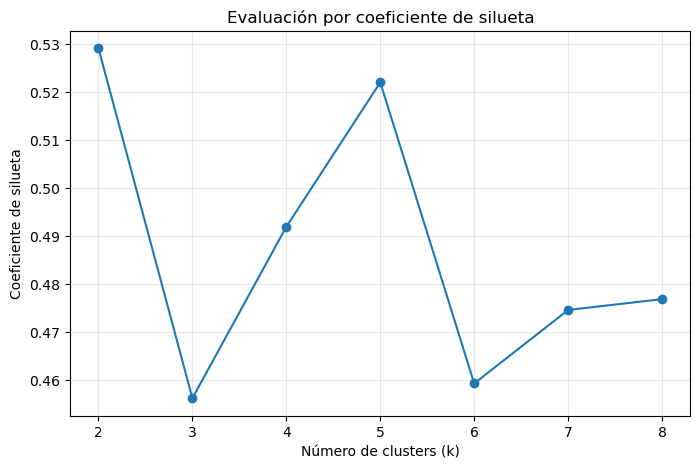

In [8]:
plt.figure(figsize=(8,5))
plt.plot(evaluacion_df["k"], evaluacion_df["inercia"], marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(evaluacion_df["k"])
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(8,5))
plt.plot(evaluacion_df["k"], evaluacion_df["silhouette"], marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de silueta")
plt.title("Evaluación por coeficiente de silueta")
plt.xticks(evaluacion_df["k"])
plt.grid(alpha=0.3)
plt.show()

# Selección de K

Aunque el coeficiente de silueta alcanza su máximo en `k=2`, la solución de **4 clusters** ofrece una segmentación comercial más útil para la práctica: separa productos de desempeño muy alto, medio, bajo y productos con presencia/ventas extremadamente reducidas. Además, `k=4` presenta una silueta de aproximadamente **0.49**, considerada una separación razonable.

# Aplicación de K-Means con 4 clusters

In [9]:
k_final = 4

modelo_final = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=20
)

agg["cluster"] = modelo_final.fit_predict(X_scaled)

print("Coeficiente de silueta:", round(
    silhouette_score(X_scaled, agg["cluster"]), 4
))

display(agg[["ITEM_CODE","BRAND","ITEM_DESCRIPTION","total_value","total_units","regions","cluster"]]
        .sort_values(["cluster","total_value"], ascending=[True,False])
        .head(20))

Coeficiente de silueta: 0.4919


,ITEM_CODE,BRAND,ITEM_DESCRIPTION,total_value,total_units,regions,cluster
7,7501058715364,VANISH,VANISH MULTIUSOS REMOV S/CLORO MANCHAS BOT 420...,42.248,2.076,2,0
60,7501058794970BP1,VANISH,VANISHOXIACTIONGOLDCRYSTALWHITEBOT900GR+MMROSA...,20.921,0.152,4,0
48,7501058790415BP1,VANISH,VANISH ROSA QUITAMANCHAS BOT 450 GR C/G MM BOT...,4.450,0.060,2,0
24,7501058717016,VANISH,VANISH OXI ACTION CRISTAL WHITE BOT 120 GR 750...,4.360,0.218,5,0
61,7501058794970BP2,VANISH,VANISHOXIACTIONGOLDROSABOT150GR+MMCRYSTALWHITE...,3.127,0.152,4,0
46,7501058788931,VANISH,VANISH MULTIUSOS DUOPACK ROSA QUITA MANCHAS 2B...,2.528,0.062,4,0
4,7501058715029,VANISH,VANISH MULTIUSOS REMOVEDOR S/CLORO DE MANCHAS ...,1.784,0.092,3,0
53,7501058793898,VANISH,VANISH ROSA MULTIUSOS REMOVEDOR MANC 3X2 BOT 9...,1.110,0.022,4,0
47,7501058789778BP1,VANISH,VANISH EXT HIGIENE REM MANCHAS GAL 4LT + VANIS...,0.180,0.002,2,0
41,7501058782694BP1,VANISH,VANISH OXI ACTION QUITAMANCHAS BOT 450G C/GMM ...,0.172,0.014,3,0


# Perfil de los clusters

In [10]:
resumen = (
    agg.groupby("cluster")
       .agg(
           productos=("ITEM_CODE", "count"),
           ventas_totales=("total_value", "sum"),
           unidades_totales=("total_units", "sum"),
           venta_promedio=("total_value", "mean"),
           unidades_promedio=("total_units", "mean"),
           regiones_promedio=("regions", "mean"),
           semanas_promedio=("weeks", "mean")
       )
       .reset_index()
       .sort_values("ventas_totales", ascending=False)
)

display(resumen.round(2))

,cluster,productos,ventas_totales,unidades_totales,venta_promedio,unidades_promedio,regiones_promedio,semanas_promedio
1,1,39,1295455.95,13464.31,33216.82,345.24,6.79,78.46
3,3,11,871854.03,41845.73,79259.46,3804.16,7.00,80.00
2,2,14,898.48,20.05,64.18,1.43,6.86,43.07
0,0,13,81.07,2.85,6.24,0.22,3.15,16.00


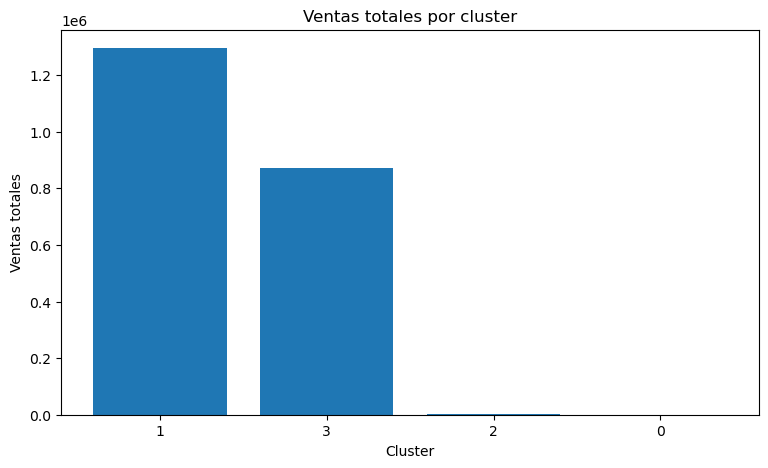

In [11]:
plt.figure(figsize=(9,5))
plt.bar(resumen["cluster"].astype(str), resumen["ventas_totales"])
plt.xlabel("Cluster")
plt.ylabel("Ventas totales")
plt.title("Ventas totales por cluster")
plt.show()

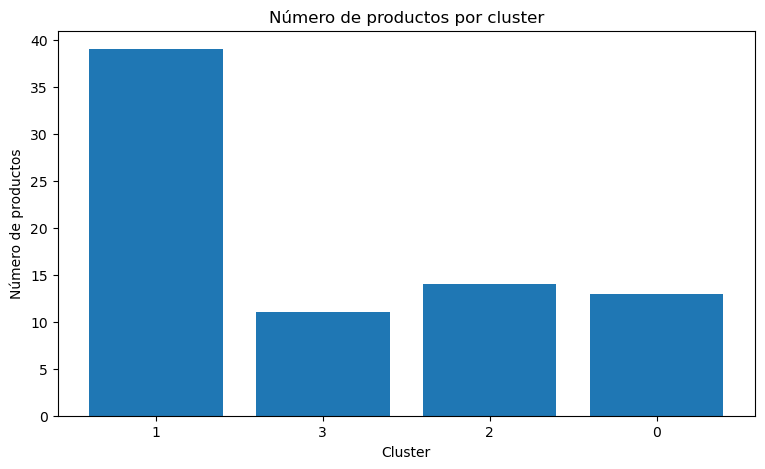

In [12]:
plt.figure(figsize=(9,5))
plt.bar(resumen["cluster"].astype(str), resumen["productos"])
plt.xlabel("Cluster")
plt.ylabel("Número de productos")
plt.title("Número de productos por cluster")
plt.show()

# Visualización mediante PCA

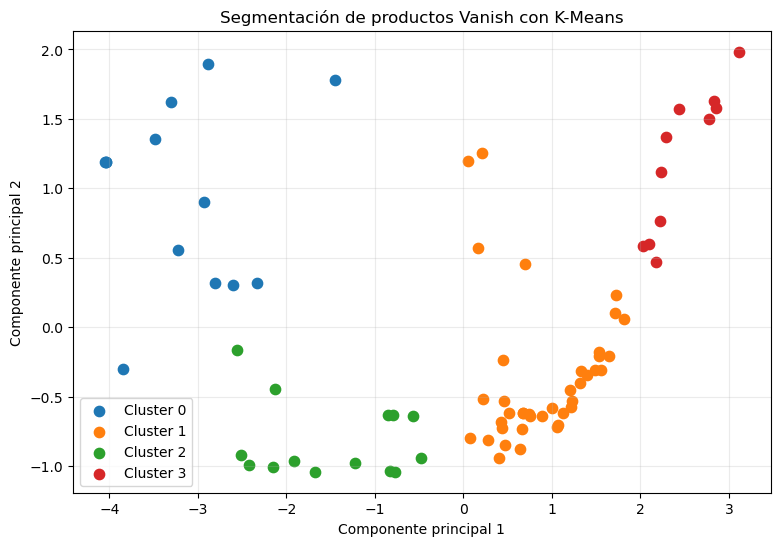

Varianza explicada por PCA: [0.7394 0.1577]
Varianza acumulada: 0.8971


In [13]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

agg["PCA1"] = X_pca[:, 0]
agg["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(9,6))
for c in sorted(agg["cluster"].unique()):
    sub = agg[agg["cluster"] == c]
    plt.scatter(sub["PCA1"], sub["PCA2"], label=f"Cluster {c}", s=55)

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("Segmentación de productos Vanish con K-Means")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Varianza explicada por PCA:", np.round(pca.explained_variance_ratio_, 4))
print("Varianza acumulada:", round(pca.explained_variance_ratio_.sum(), 4))

# Productos representativos

In [14]:
for c, grupo in agg.sort_values("total_value", ascending=False).groupby("cluster"):
    print(f"\nCLUSTER {c}")
    display(
        grupo[["ITEM_CODE","BRAND","ITEM_DESCRIPTION","FORMAT",
               "total_value","total_units","regions"]]
        .head(5)
    )


CLUSTER 0


,ITEM_CODE,BRAND,ITEM_DESCRIPTION,FORMAT,total_value,total_units,regions
7,7501058715364,VANISH,VANISH MULTIUSOS REMOV S/CLORO MANCHAS BOT 420...,LIQUIDO,42.248,2.076,2
60,7501058794970BP1,VANISH,VANISHOXIACTIONGOLDCRYSTALWHITEBOT900GR+MMROSA...,POLVO,20.921,0.152,4
48,7501058790415BP1,VANISH,VANISH ROSA QUITAMANCHAS BOT 450 GR C/G MM BOT...,POLVO,4.450,0.060,2
24,7501058717016,VANISH,VANISH OXI ACTION CRISTAL WHITE BOT 120 GR 750...,POLVO,4.360,0.218,5
61,7501058794970BP2,VANISH,VANISHOXIACTIONGOLDROSABOT150GR+MMCRYSTALWHITE...,POLVO,3.127,0.152,4



CLUSTER 1


,ITEM_CODE,BRAND,ITEM_DESCRIPTION,FORMAT,total_value,total_units,regions
20,7501058716767,VANISH,VANISH ROSA QUITAMANCHAS GEL BOT 3.8 LT PROM E...,GEL,132086.569,874.500,7
40,7501058757890,VANISH,VANISH PODER O2 CRYSTAL WHITE BOTE 450 GR 750...,POLVO,111346.252,1187.546,7
39,7501058757791,VANISH,VANISH BOT. 4000 ML. 7501058757791,LIQUIDO,105346.441,582.632,7
43,7501058784353,VANISH,VANISH INTELLIGENCE POLVO BOTE 450 GR NAL 7501...,POLVO,96865.268,1042.715,7
28,7501058751195,VANISH,VANISH WHITE BOTELLA 900 ML 7501058751195,LIQUIDO,92228.200,1687.384,7



CLUSTER 2


,ITEM_CODE,BRAND,ITEM_DESCRIPTION,FORMAT,total_value,total_units,regions
18,7501058716453,VANISH,VANISH MULTIUSOS ROSA REMOV/MAN SUPER AHORRO D...,LIQUIDO,340.424,5.258,7
58,7501058794963BP1,VANISH,VANISHOXIACTIONGOLDROSABOT900GR+MMCRYSTALWHITE...,POLVO,205.762,1.868,7
69,7501058796950BP1,VANISH,VANISHOXIACTIONROSAGELDOYPACK500ML+PLANCHYTEXB...,GEL,175.157,4.652,7
65,7501058796837,VANISH,VANISH SUPERBARRAGOLDC/ENZIMA SUPERPRECIO 2PZA...,BARRA,51.661,2.482,7
59,7501058794963BP2,VANISH,VANISHOXIACTIONGOLDCRYSTALWHITEBOT150GR+MMROSA...,POLVO,30.754,1.868,7



CLUSTER 3


,ITEM_CODE,BRAND,ITEM_DESCRIPTION,FORMAT,total_value,total_units,regions
70,7503002319529,VANISH,VANISH LIQUIDO BOTELLA 925ML NAL. 7503002319529,LIQUIDO,162102.968,2937.696,7
25,7501058717023,VANISH,VANISH ROSA QUITAMANCHAS GEL MULTIUSOS POUCH 4...,GEL,158725.720,7024.094,7
26,7501058717030,VANISH,VANISH CRYSTAL WHITE QUITAMANCHAS GEL POUCH 45...,GEL,114642.364,5046.584,7
2,7501058714596,VANISH,VANISH SUPER BARRA QUITA MANCHAS 68GR 75010587...,BARRA,99483.947,8059.988,7
76,7891035040276,VANISH,VANISH SUPER BARRA WHITE QUITA MANCHAS 68GR 78...,BARRA,86985.746,6988.174,7


# Interpretación de resultados

**Cluster 3 — líderes de alto desempeño.**  
Es el segmento de mayor valor comercial. Está formado por pocos productos, pero concentra ventas y unidades muy superiores al resto. Son candidatos para proteger disponibilidad, distribución y acciones de fidelización.

**Cluster 1 — productos de desempeño medio/alto.**  
Es el grupo más numeroso y presenta presencia amplia en las regiones. Constituye una base importante para crecimiento y optimización del portafolio.

**Cluster 2 — productos de baja rotación con presencia amplia.**  
Estos productos llegan a muchas regiones, pero generan ventas relativamente bajas. Representan oportunidades para revisar precio, promoción, surtido, posicionamiento o rentabilidad.

**Cluster 0 — productos de desempeño muy bajo o presencia limitada.**  
Son productos con muy pocas unidades y bajo valor de ventas, además de una cobertura regional menor. Conviene evaluar si existe una razón comercial, de distribución o de ciclo de vida que explique su comportamiento.

> **Nota:** los nombres de los clusters son interpretaciones de negocio; el algoritmo únicamente identifica grupos estadísticamente similares.

# Recomendaciones estratégicas

In [15]:
recomendaciones = pd.DataFrame({
    "segmento": [
        "Cluster 3: líderes",
        "Cluster 1: base comercial",
        "Cluster 2: baja rotación",
        "Cluster 0: presencia limitada"
    ],
    "accion": [
        "Priorizar disponibilidad, distribución, promociones selectivas y protección de los productos líderes.",
        "Identificar productos con potencial para migrar al segmento líder mediante precio, promoción y mayor visibilidad.",
        "Analizar rentabilidad, elasticidad, promociones y desempeño por región antes de ampliar inventario.",
        "Evaluar descontinuación, reposicionamiento, distribución selectiva o campañas específicas."
    ]
})
display(recomendaciones)

,segmento,accion
0,Cluster 3: líderes,"Priorizar disponibilidad, distribución, promoc..."
1,Cluster 1: base comercial,Identificar productos con potencial para migra...
2,Cluster 2: baja rotación,"Analizar rentabilidad, elasticidad, promocione..."
3,Cluster 0: presencia limitada,"Evaluar descontinuación, reposicionamiento, di..."


# Exportación de resultados

In [19]:
resultado_final = agg.copy()

resultado_final.to_csv(
    "/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 27/proyecto/Vanish_Clustering_Resultados.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo generado: Vanish_Clustering_Resultados.csv")

Archivo generado: Vanish_Clustering_Resultados.csv


# Conclusión

El clustering permitió segmentar los productos Vanish con base en su comportamiento de ventas y cobertura. La solución de cuatro grupos facilita una lectura comercial: productos líderes, productos de desempeño medio/alto, productos de baja rotación y productos con desempeño muy bajo o presencia limitada.

El análisis muestra que **la marca no depende de todos sus productos de la misma manera**: un grupo reducido concentra una parte importante del valor comercial, mientras que otros productos presentan oportunidades de optimización. Por ello, la estrategia puede diferenciarse por segmento en lugar de aplicar las mismas acciones a todo el portafolio.

El modelo debe utilizarse como herramienta de apoyo a la decisión y complementarse con variables adicionales —margen, precio, promociones, inventario, distribución y temporalidad— para tomar decisiones comerciales definitivas.